# AIM608 End-term Project 4 — A Hybrid Recommender on a User–Film–Content Graph

**What this notebook does.** It builds and evaluates, on MovieLens *latest-small*, every item in the brief:

| Brief item | Where |
|---|---|
| Warm-up: personalised PageRank by power iteration | §2 |
| 1. Collaborative filtering (item-based; random walk with restart) | §4, §5 |
| 2. Content similarity (sentence-transformers, k-NN film graph) | §3 |
| 3. The hybrid (random walk on both edge types, vary content weight) | §5, §7 |
| 4. Other approaches (popularity-discounted walk, late fusion, node2vec/DeepWalk) | §5 |
| Demo (side-by-side recommendations; new film with no ratings) | §10 |
| Measures: accuracy, cold start, popularity, communities of taste, weight of content | §6–§9 |

**Protocol.** Every number comes from code in `src/hybrid_rec.py`, executed here. Ratings are split **before any edge is built** (20 % of each user's ratings hidden; a further 15 % of the remaining training ratings is used as a validation set for choosing hyper-parameters, so the test set is never used for tuning). A film is *liked* if rated ≥ 4. Results are averaged over 3 random splits (seeds 0, 1, 2).

**GenAI declaration.** Claude Code (Anthropic, model Claude Sonnet 5.5) was used to help write the code and the report. All design decisions, the experiments and their interpretation were reviewed by the authors.
**Libraries.** numpy, scipy, pandas, scikit-learn, networkx, matplotlib, PyTorch, sentence-transformers (`all-MiniLM-L6-v2`, Reimers & Gurevych 2019). Full references are in the report.

In [1]:
import sys, os, pickle, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, "src")
import numpy as np, pandas as pd, scipy.sparse as sp, scipy.sparse.linalg as spl
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import hybrid_rec as H

os.makedirs("report/figs", exist_ok=True); os.makedirs("report/tables", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 10})
COL = {"Popularity":"#9e9e9e","Item-based CF":"#1f77b4","Content only (profile)":"#2ca02c",
       "RWR (ratings only)":"#ff7f0e","RWR + popularity discount":"#d4a017","Late fusion (CF+content)":"#8c564b",
       "Hybrid RWR":"#d62728","Hybrid RWR + popularity discount":"#9467bd","node2vec on hybrid graph":"#17becf","Random":"#bdbdbd"}
def savefig(name):
    plt.savefig(f"report/figs/{name}.pdf", bbox_inches="tight"); plt.savefig(f"report/figs/{name}.png", dpi=200, bbox_inches="tight")

R, M, T = H.load_data()
nU, nI = int(R.u.max()) + 1, len(M)
print(f"{nU} users, {nI} films ({R.i.nunique()} rated), {len(R)} ratings, {len(T)} tag applications")
print(f"density of the rating matrix: {len(R)/(nU*nI):.4f}")

610 users, 9742 films (9724 rated), 100836 ratings, 3683 tag applications
density of the rating matrix: 0.0170


## 1. The data and the network

*Users* and *films* are nodes; a *rating* is an edge weighted by the rating; two films are joined by a *content edge* if their content is similar. First, what the rating network looks like — it has the heavy tails typical of real bipartite networks.

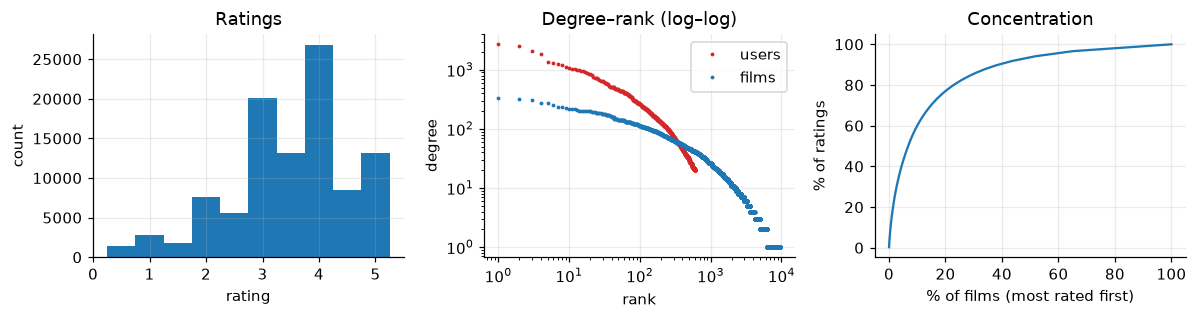

top 10% most-rated films receive 60.0% of all ratings; median film has 3 ratings; 62% of rated films have fewer than 5 ratings; 18 films have none.


In [2]:
udeg = R.groupby("u").size(); fdeg = R.groupby("i").size()
fig, ax = plt.subplots(1, 3, figsize=(11, 3))
ax[0].hist(R.rating, bins=np.arange(.25, 5.5, .5), color="#1f77b4"); ax[0].set_xlabel("rating"); ax[0].set_ylabel("count"); ax[0].set_title("Ratings")
for d, nm, c in [(udeg, "users", "#d62728"), (fdeg, "films", "#1f77b4")]:
    s = np.sort(d.values)[::-1]; ax[1].loglog(np.arange(1, len(s)+1), s, ".", ms=3, label=nm, color=c)
ax[1].set_xlabel("rank"); ax[1].set_ylabel("degree"); ax[1].set_title("Degree–rank (log–log)"); ax[1].legend()
cum = np.sort(fdeg.values)[::-1].cumsum() / fdeg.sum()
ax[2].plot(np.arange(1, len(cum)+1)/len(cum)*100, cum*100); ax[2].set_xlabel("% of films (most rated first)"); ax[2].set_ylabel("% of ratings"); ax[2].set_title("Concentration")
plt.tight_layout(); savefig("fig_data"); plt.show()
top10pct = fdeg.sort_values(ascending=False).iloc[:int(.1*len(fdeg))].sum()/fdeg.sum()
print(f"top 10% most-rated films receive {top10pct:.1%} of all ratings; median film has {int(fdeg.median())} ratings; "
      f"{(fdeg<5).mean():.0%} of rated films have fewer than 5 ratings; {(M.movieId.isin(R.movieId)==False).sum()} films have none.")

## 2. Warm-up — random walk with restart by power iteration

On the **user–film graph alone** (no content edges) we compute personalised PageRank from one user. The walker, from a node, follows an edge with probability proportional to its weight and, at every step, jumps back to the start user with probability $c$:
$$ r \;\leftarrow\; (1-c)\,P\,r + c\,e_u ,\qquad P=\text{column-stochastic transition matrix}. $$
We check the implementation in **three independent ways**: (i) the iteration converges geometrically at rate $1-c$; (ii) it equals the closed-form solution $r=c\,(I-(1-c)P)^{-1}e_u$; (iii) it matches the visit frequencies of an actual simulated random walk. Then we check the brief's question: *do films rated highly by users similar to this user rank near the top?*

power iteration: 175 iterations to L1-change < 1e-12;  sum(r) = 1.000000004852
max |power iteration − exact solve|       = 5.33e-15
Spearman(power iteration, Monte-Carlo walk) over films = 0.950


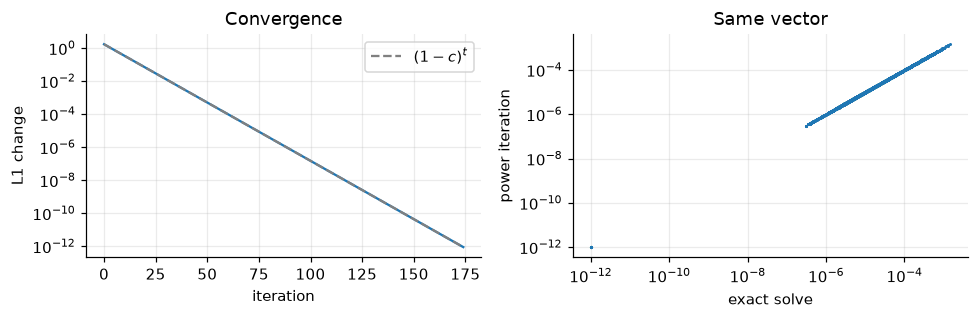

In [3]:
ctx_full = H.Ctx(R, R.iloc[:0], nU, nI)                 # all ratings; no test set (used for warm-up, demo, communities)
C0 = sp.csr_matrix((nI, nI))                              # no content edges -> pure user-film graph
P0 = H.build_P(ctx_full.A, C0, 0.0).astype(np.float64)
u0 = 104                                                  # userId 105: loves both 3 Idiots and Taare Zameen Par (the brief's example)
c = 0.15
r, hist = H.power_iteration(P0, u0, c=c)
N = P0.shape[0]; e = np.zeros(N); e[u0] = 1
r_exact = c * spl.spsolve(sp.identity(N, format="csc") - (1-c)*P0.tocsc(), e)
r_mc = H.monte_carlo_rwr(P0, u0, c=c)
print(f"power iteration: {len(hist)} iterations to L1-change < 1e-12;  sum(r) = {r.sum():.12f}")
print(f"max |power iteration − exact solve|       = {np.abs(r - r_exact).max():.2e}")
print(f"Spearman(power iteration, Monte-Carlo walk) over films = {spearmanr(r[nU:], r_mc[nU:])[0]:.3f}")
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].semilogy(hist); ax[0].plot(hist[0]*(1-c)**np.arange(len(hist)), "--", color="gray", label=r"$(1-c)^t$"); ax[0].set_xlabel("iteration"); ax[0].set_ylabel("L1 change"); ax[0].legend(); ax[0].set_title("Convergence")
ax[1].loglog(r_exact[nU:]+1e-12, r[nU:]+1e-12, ".", ms=2); ax[1].set_xlabel("exact solve"); ax[1].set_ylabel("power iteration"); ax[1].set_title("Same vector")
plt.tight_layout(); savefig("fig_warmup"); plt.show()

In [4]:
title = M.title.values
A = ctx_full.A
film_r = r[nU:].copy(); film_r[ctx_full.seen_c[ctx_full.seen_r == u0]] = -1       # unseen films only
top = np.argsort(-film_r)[:10]
# "similar users" = the other users the walker visits most
nbrs = np.argsort(-r[:nU])[1:31]
Anb = A[nbrs]
nb_cnt = np.asarray((Anb > 0).sum(0)).ravel(); nb_sum = np.asarray(Anb.sum(0)).ravel()
tab = pd.DataFrame({"film": title[top], "RWR score": film_r[top].round(5), "rated by (of 30 nearest users)": nb_cnt[top],
                    "their mean rating": (nb_sum[top]/np.maximum(nb_cnt[top], 1)).round(2), "ratings overall": ctx_full.pop[top]})
print("User 105 rated (>=4.5):", ", ".join(title[A[u0].indices[A[u0].data >= 4.5]][:8]), "...")
display(tab)
# systematic check: neighbours' mean rating of RWR-top-10 vs. 10 random unseen films
rng = np.random.default_rng(0); unseen = np.where(film_r >= 0)[0]
def nb_mean(ix): m = nb_cnt[ix] > 0; return (nb_sum[ix][m]/nb_cnt[ix][m]).mean(), m.mean()
print("RWR top-10 : mean rating by similar users = %.2f (share rated by any of them %.0f%%)" % (nb_mean(top)[0], 100*nb_mean(top)[1]))
rand = np.mean([nb_mean(rng.choice(unseen, 10, replace=False))[0] for _ in range(200)])
print("random 10  : mean rating by similar users = %.2f (over those they rated)" % rand)

User 105 rated (>=4.5): Casino (1995), Seven (a.k.a. Se7en) (1995), Usual Suspects, The (1995), Taxi Driver (1976), Burnt by the Sun (Utomlyonnye solntsem) (1994), Léon: The Professional (a.k.a. The Professional) (Léon) (1994), Pulp Fiction (1994), Three Colors: Red (Trois couleurs: Rouge) (1994) ...


,film,RWR score,rated by (of 30 nearest users),their mean rating,ratings overall
0,Star Wars: Episode V - The Empire Strikes Back...,0.00074,28,4.38,211
1,Star Wars: Episode VI - Return of the Jedi (1983),0.00066,28,4.27,196
2,Toy Story (1995),0.00065,26,3.77,215
3,Jurassic Park (1993),0.00065,28,3.64,238
4,Back to the Future (1985),0.00057,28,3.96,171
5,Apollo 13 (1995),0.00055,18,3.31,201
6,"Lion King, The (1994)",0.00053,22,3.86,172
7,"Fugitive, The (1993)",0.00052,21,3.81,190
8,Independence Day (a.k.a. ID4) (1996),0.00051,27,3.31,202
9,Aladdin (1992),0.00051,20,3.78,183


RWR top-10 : mean rating by similar users = 3.81 (share rated by any of them 100%)
random 10  : mean rating by similar users = 3.11 (over those they rated)


## 3. Content similarity — sentence embeddings and a k-NN film graph

Each film is described by a short text: *title + genres + user tags* (tags exist for ≈ 1.6 k films only, which is exactly why many films are content-poor). The text is embedded with `sentence-transformers` (`all-MiniLM-L6-v2`, 384 dimensions), vectors are L2-normalised, and each film is linked to its **k most similar films** by cosine similarity (the graph is symmetrised: an edge is kept if either film lists the other).

In [5]:
texts = H.film_text(M, T)
E = H.embed_texts(texts, cache="results/emb.npy")
print(E.shape); print(texts[0]); print(texts[M.index[M.title.str.startswith("3 Idiots")][0]])
KS = [5, 10, 20, 40]
Cs = {k: H.knn_graph(E, k) for k in KS}
C20 = Cs[20]
print({k: f"{Cs[k].nnz//2} edges" for k in KS})
def neighbours(name, n=6):
    i = M.index[M.title.str.contains(name, regex=False)][0]
    row = C20[i].toarray().ravel(); j = np.argsort(-row)[:n]
    return pd.DataFrame({"film": title[j], "genres": M.genres.values[j], "cosine": row[j].round(3)})
for nm in ["3 Idiots", "Toy Story (1995)", "Like Stars on Earth"]:
    print("\nNearest content neighbours of", nm); display(neighbours(nm))

(9742, 384)
Toy Story. Genres: Adventure, Animation, Children, Comedy, Fantasy. Tags: fun, pixar
3 Idiots. Genres: Comedy, Drama, Romance. Tags:


{5: '40986 edges', 10: '83187 edges', 20: '169067 edges', 40: '340807 edges'}

Nearest content neighbours of 3 Idiots


,film,genres,cosine
0,"Idiots, The (Idioterne) (1998)",Comedy|Drama,0.882
1,Smart People (2008),Comedy|Drama|Romance,0.812
2,Idiots and Angels (2008),Animation|Drama|Fantasy,0.802
3,Guess Who (2005),Comedy|Romance,0.792
4,"Crazy, Stupid, Love. (2011)",Comedy|Drama|Romance,0.788
5,Threesome (1994),Comedy|Romance,0.787



Nearest content neighbours of Toy Story (1995)


,film,genres,cosine
0,Toy Story 3 (2010),Adventure|Animation|Children|Comedy|Fantasy|IMAX,0.878
1,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,0.851
2,Toys (1992),Comedy|Fantasy,0.820
3,"Bug's Life, A (1998)",Adventure|Animation|Children|Comedy,0.816
4,"Toy, The (1982)",Comedy,0.776
5,Shrek (2001),Adventure|Animation|Children|Comedy|Fantasy|Ro...,0.769



Nearest content neighbours of Like Stars on Earth


,film,genres,cosine
0,O (2001),Drama,0.795
1,Ju Dou (1990),Drama,0.788
2,W. (2008),Drama,0.779
3,L.I.E. (2001),Drama,0.773
4,Solas (1999),Drama,0.773
5,"Visit, The (2000)",Drama,0.772


In [6]:
# Does the embedding capture genre?  Jaccard of genre sets: content neighbours vs random pairs.
G = M.genres.str.split("|").apply(set).values
jac = lambda a, b: len(a & b) / max(len(a | b), 1)
rng = np.random.default_rng(0); idx = rng.choice(nI, 3000, replace=False)
nb_j = np.mean([jac(G[i], G[np.argmax(C20[i].toarray().ravel())]) for i in idx])
rd_j = np.mean([jac(G[i], G[j]) for i, j in zip(idx, rng.choice(nI, 3000))])
print(f"mean genre Jaccard: nearest content neighbour {nb_j:.2f}  vs  random film {rd_j:.2f}")

mean genre Jaccard: nearest content neighbour 0.63  vs  random film 0.17


## 4. Collaborative filtering and the hybrid — the models

All models return a score for every (user, film) pair; films the user already rated in *training* are excluded.

* **Item-based CF** — project the user–film graph onto films: $S=\tilde A^{\top}\tilde A$ with rating columns L2-normalised (cosine; raw co-rating counts would simply favour popular films). Score = sum of similarities to the films the user liked.
* **RWR (ratings only)** — personalised PageRank from the user on the user–film graph.
* **Content only** — cosine between a film's embedding and the user's liked-film profile (no graph).
* **Hybrid RWR** — the same walk on the graph with **both** edge types. From a film the walker takes a *content edge* with probability $\lambda$ and a *rating edge* with probability $1-\lambda$ (so $\lambda$ is the weight of content against rating edges). A film with no ratings can only be left through content edges — this is what makes cold-start films reachable.
* **Popularity-discounted** variants — the walk's stationary mass is roughly proportional to degree, so scores are divided by $(1+n_i)^\beta$ ($n_i$ = ratings of film $i$).
* **Late fusion** — a *non-graph* hybrid: a convex combination of min–max normalised item-CF and content scores (a baseline for the graph hybrid).
* **node2vec** — embeddings of all nodes of the hybrid graph from random walks + skip-gram with negative sampling (our own PyTorch implementation; walks are first-order, i.e. node2vec with $p=q=1$ = DeepWalk); score = cosine(user, film).

**Hyper-parameters** (restart probability $c$, content weight $\lambda$, discount $\beta$, fusion weight $\alpha$) are chosen on the validation split only. Number of content neighbours: $k=20$.

## 5. Run the experiments (3 random splits)

`src/run_all.py` runs, for each seed: split → tune on validation → all methods on test → λ sweep → k sweep → c sweep → cold-start experiment. Results are cached in `results/seed*.pkl` (delete them to re-run; ≈ 10 min).

In [7]:
from run_all import run_all
res = run_all([0, 1, 2])
for s in res: print("seed", s["seed"], "tuned on validation:", s["params"])

seed 0 tuned on validation: {'c': 0.7, 'lam': 0.1, 'lam_debias': 0.05, 'beta_cf': 0.5, 'beta_hyb': 0.2, 'alpha': 0.05, 'k': 20}
seed 1 tuned on validation: {'c': 0.7, 'lam': 0.1, 'lam_debias': 0.05, 'beta_cf': 0.5, 'beta_hyb': 0.2, 'alpha': 0.05, 'k': 20}
seed 2 tuned on validation: {'c': 0.7, 'lam': 0.1, 'lam_debias': 0.1, 'beta_cf': 0.5, 'beta_hyb': 0.0, 'alpha': 0.2, 'k': 20}


In [8]:
def agg(getter, fmt="{:.3f}"):
    # getter(result) -> value; returns mean, std over seeds
    v = np.array([getter(s) for s in res], float); return v.mean(), v.std(ddof=0)
def table(section, metrics, names, fmt="{:.3f}", extra=None):
    rows = {}
    for n in names:
        rows[n] = {lab: "%s ± %s" % (fmt.format(agg(lambda s: s[section][n][m])[0]), fmt.format(agg(lambda s: s[section][n][m])[1]))
                   for m, lab in metrics.items()}
    return pd.DataFrame(rows).T
def meanstd(section, n, m): return agg(lambda s: s[section][n][m])

## 6. Accuracy — hide 20 % of each user's ratings

precision@10 = fraction of the 10 recommended films that the user liked in the hidden set; recall@10 = fraction of the user's hidden liked films found in the top 10 (NDCG@10 added as a rank-aware summary). Mean ± s.d. over 3 splits; ≈ 600 users per split.

,precision@10,recall@10,NDCG@10
Popularity,0.119 ± 0.003,0.097 ± 0.001,0.157 ± 0.003
Item-based CF,0.174 ± 0.004,0.169 ± 0.003,0.231 ± 0.002
Content only (profile),0.003 ± 0.001,0.006 ± 0.002,0.007 ± 0.002
RWR (ratings only),0.174 ± 0.004,0.169 ± 0.004,0.235 ± 0.005
RWR + popularity discount,0.197 ± 0.005,0.189 ± 0.001,0.266 ± 0.006
Late fusion (CF+content),0.172 ± 0.002,0.169 ± 0.003,0.232 ± 0.001
Hybrid RWR,0.184 ± 0.005,0.179 ± 0.003,0.251 ± 0.006
Hybrid RWR + popularity discount,0.187 ± 0.005,0.184 ± 0.004,0.256 ± 0.007
node2vec on hybrid graph,0.045 ± 0.003,0.068 ± 0.005,0.067 ± 0.006


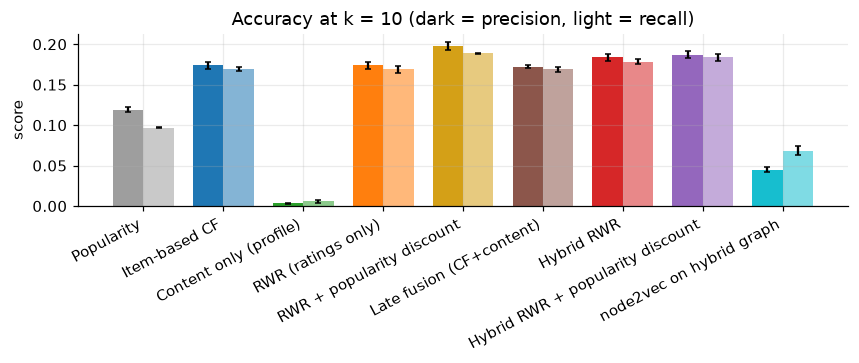

In [9]:
names = list(res[0]["main"].keys())
acc = table("main", {"p": "precision@10", "r": "recall@10", "ndcg": "NDCG@10"}, names)
display(acc)
open("report/tables/accuracy.tex", "w").write(acc.to_latex(escape=True, column_format="lccc"))
fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(len(names)); w = .38
for j, (m, lab, a) in enumerate([("p", "precision@10", 1), ("r", "recall@10", .55)]):
    mu = [meanstd("main", n, m)[0] for n in names]; sd = [meanstd("main", n, m)[1] for n in names]
    ax.bar(x + (j-.5)*w, mu, w, yerr=sd, color=[COL[n] for n in names], alpha=a, label=lab, capsize=2)
ax.set_xticks(x); ax.set_xticklabels(names, rotation=28, ha="right"); ax.set_ylabel("score"); ax.set_title("Accuracy at k = 10 (dark = precision, light = recall)")
plt.tight_layout(); savefig("fig_accuracy"); plt.show()

## 7. The weight of content — at what λ does accuracy peak?

λ = 0 is the ratings-only walk; λ = 1 means a walker on a film always follows content edges (users re-enter only through the restart). Left: accuracy on **warm** films (the standard hold-out). Right: tail share (fraction of recommendations outside the top 10 % most-rated films).

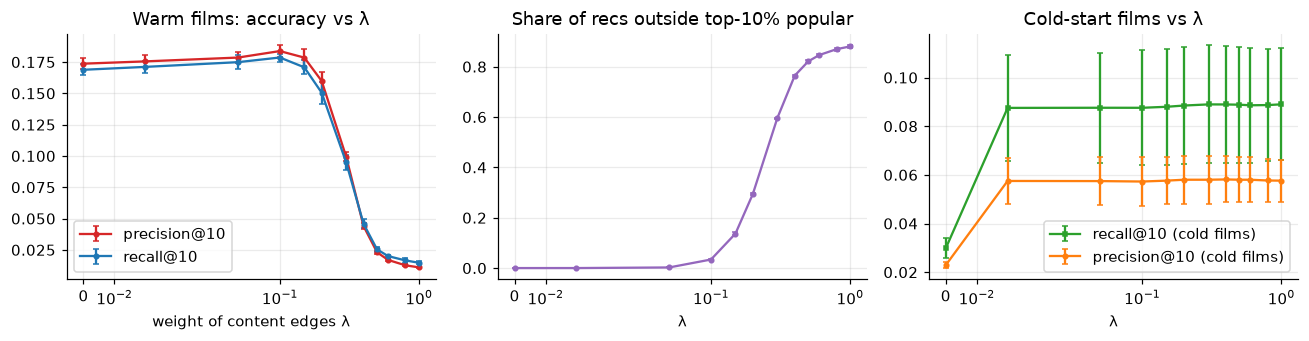

,λ,precision@10,recall@10,tail share,cold recall@10
0,0,0.1737 ± 0.0044,0.1688,0.000,0.0298
1,0.02,0.1755 ± 0.0047,0.1711,0.000,0.0875
2,0.05,0.1786 ± 0.0046,0.1749,0.003,0.0876
3,0.1,0.1838 ± 0.0046,0.1786,0.034,0.0876
4,0.15,0.1785 ± 0.0069,0.1708,0.137,0.0880
5,0.2,0.1599 ± 0.0068,0.1505,0.295,0.0885
6,0.3,0.0993 ± 0.0037,0.0948,0.596,0.0890
7,0.4,0.0440 ± 0.0025,0.0458,0.764,0.0889
8,0.5,0.0231 ± 0.0014,0.0254,0.821,0.0888
9,0.6,0.0170 ± 0.0005,0.0200,0.846,0.0886


argmax of precision@10 over λ for each split: [0.1, 0.1, 0.1] | of the mean curve: 0.1
gain of best λ over λ=0 (paired, per split): [0.0078 0.0086 0.0138]


In [10]:
lams = H.LAMS
def curve(section, m): return np.array([[s[section][l][m] for l in lams] for s in res])
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
for m, lab, col in [("p", "precision@10", "#d62728"), ("r", "recall@10", "#1f77b4")]:
    cv = curve("lam_sweep", m); ax[0].errorbar(lams, cv.mean(0), cv.std(0), marker="o", ms=3, label=lab, color=col, capsize=2)
ax[0].set_xlabel("weight of content edges λ"); ax[0].set_title("Warm films: accuracy vs λ"); ax[0].legend()
ax[0].set_xscale("symlog", linthresh=.05)
cv = curve("lam_sweep", "tail"); ax[1].errorbar(lams, cv.mean(0), cv.std(0), marker="o", ms=3, color="#9467bd", capsize=2)
ax[1].set_xscale("symlog", linthresh=.05); ax[1].set_xlabel("λ"); ax[1].set_title("Share of recs outside top-10% popular")
cv = curve("cold_sweep", "r"); ax[2].errorbar(lams, cv.mean(0), cv.std(0), marker="s", ms=3, color="#2ca02c", capsize=2, label="recall@10 (cold films)")
cv = curve("cold_sweep", "p"); ax[2].errorbar(lams, cv.mean(0), cv.std(0), marker="o", ms=3, color="#ff7f0e", capsize=2, label="precision@10 (cold films)")
ax[2].set_xscale("symlog", linthresh=.05); ax[2].set_xlabel("λ"); ax[2].set_title("Cold-start films vs λ"); ax[2].legend()
plt.tight_layout(); savefig("fig_lambda"); plt.show()
cvp = curve("lam_sweep", "p")
sw = pd.DataFrame({"λ": [f"{l:g}" for l in lams], "precision@10": [f"{a:.4f} ± {b:.4f}" for a, b in zip(cvp.mean(0), cvp.std(0))],
                   "recall@10": [f"{a:.4f}" for a in curve("lam_sweep", "r").mean(0)],
                   "tail share": [f"{a:.3f}" for a in curve("lam_sweep", "tail").mean(0)],
                   "cold recall@10": [f"{a:.4f}" for a in curve("cold_sweep", "r").mean(0)]})
display(sw); open("report/tables/lambda.tex", "w").write(sw.to_latex(index=False, escape=True, column_format="lcccc"))
best = [lams[int(np.argmax(cvp[i]))] for i in range(len(res))]
print("argmax of precision@10 over λ for each split:", best, "| of the mean curve:", lams[int(np.argmax(cvp.mean(0)))])
print("gain of best λ over λ=0 (paired, per split):", np.round(cvp.max(1) - cvp[:, 0], 4))

In [11]:
# robustness: number of content neighbours k, and restart probability c (hybrid, at the validated lambda)
ks = list(res[0]["k_sweep"].keys()); cs = list(res[0]["c_sweep"].keys())
kk = pd.DataFrame({"k": ks, "precision@10": [f"{agg(lambda s: s['k_sweep'][k]['p'])[0]:.4f}" for k in ks],
                   "recall@10": [f"{agg(lambda s: s['k_sweep'][k]['r'])[0]:.4f}" for k in ks]})
cc = pd.DataFrame({"c": [f"{c:g}" for c in cs], "precision@10": [f"{agg(lambda s: s['c_sweep'][c]['p'])[0]:.4f}" for c in cs],
                   "recall@10": [f"{agg(lambda s: s['c_sweep'][c]['r'])[0]:.4f}" for c in cs]})
display(kk); display(cc)
kk.to_latex("report/tables/ksweep.tex", index=False, column_format="lcc"); cc.to_latex("report/tables/csweep.tex", index=False, column_format="lcc")

,k,precision@10,recall@10
0,5,0.1768,0.1596
1,10,0.1861,0.1765
2,20,0.1838,0.1786
3,40,0.1805,0.1765


,c,precision@10,recall@10
0,0.15,0.1539,0.1425
1,0.3,0.1662,0.1583
2,0.5,0.1764,0.1725
3,0.7,0.1838,0.1786
4,0.85,0.1677,0.1579


## 8. Cold start — hide *all* ratings of 10 % of the films

We choose 10 % of the films that have ≥ 5 ratings, delete every rating of those films from training (they become isolated from users in the rating graph) and rank **only these cold films** for every user (the "new releases shelf" scenario); relevant = the user liked the film (hidden rating ≥ 4). Pure collaborative methods have no information about these films, so their ranking is random — the *Random* row shows what chance gives. We also measure the **reverse direction** from the brief: for each cold film, rank users and measure precision@10 over the users who liked it (*lift* = precision divided by the film's base rate of likers, so random ≈ 1).

cold films per split: [365, 365, 365]


,precision@10,recall@10,NDCG@10,user-side P@10,user-side lift
Random,0.021 ± 0.001,0.026 ± 0.004,0.025 ± 0.002,0.019 ± 0.003,1.03 ± 0.30
Item-based CF,0.023 ± 0.001,0.029 ± 0.003,0.029 ± 0.003,0.023 ± 0.004,1.28 ± 0.29
RWR (ratings only),0.023 ± 0.001,0.030 ± 0.004,0.030 ± 0.002,0.023 ± 0.004,1.28 ± 0.29
Content only (profile),0.025 ± 0.002,0.035 ± 0.006,0.037 ± 0.001,0.032 ± 0.005,2.28 ± 0.26
Hybrid RWR,0.057 ± 0.010,0.088 ± 0.024,0.082 ± 0.019,0.044 ± 0.004,2.94 ± 0.39
node2vec on hybrid graph,0.053 ± 0.001,0.079 ± 0.002,0.079 ± 0.002,0.054 ± 0.004,3.20 ± 0.29


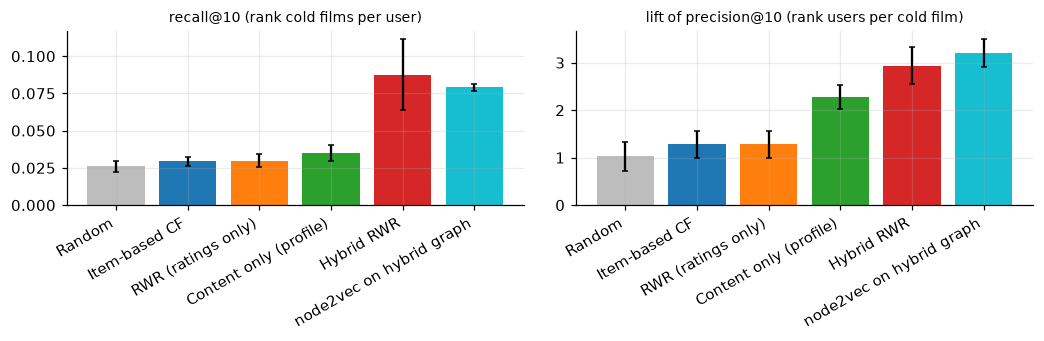

In [12]:
cnames = list(res[0]["cold_main"].keys())
cold = table("cold_main", {"p": "precision@10", "r": "recall@10", "ndcg": "NDCG@10", "user_p": "user-side P@10"}, cnames)
cold["user-side lift"] = [ "%.2f ± %.2f" % meanstd("cold_main", n, "user_lift") for n in cnames]
print("cold films per split:", [s["n_cold"] for s in res]); display(cold)
open("report/tables/cold.tex", "w").write(cold.to_latex(escape=True, column_format="lccccc"))
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.2))
for a, m, lab in [(ax[0], "r", "recall@10 (rank cold films per user)"), (ax[1], "user_lift", "lift of precision@10 (rank users per cold film)")]:
    mu = [meanstd("cold_main", n, m)[0] for n in cnames]; sd = [meanstd("cold_main", n, m)[1] for n in cnames]
    a.bar(range(len(cnames)), mu, yerr=sd, color=[COL[n] for n in cnames], capsize=2); a.set_xticks(range(len(cnames))); a.set_xticklabels(cnames, rotation=30, ha="right"); a.set_title(lab, fontsize=9)
plt.tight_layout(); savefig("fig_cold"); plt.show()

## 9. Popularity — do the methods recommend mostly popular films?

*Tail share* = fraction of the recommended films outside the top 10 % most-rated films (so a method that only recommends blockbusters scores ≈ 0). We also report *coverage* (fraction of the whole catalogue that appears in at least one user's top 10) and the mean log-popularity of recommended films.

,precision@10,outside top-10% popular,catalogue coverage,mean log(1+#ratings)
Popularity,0.119,0.000 ± 0.000,0.005 ± 0.000,5.265 ± 0.001
Item-based CF,0.174,0.029 ± 0.003,0.050 ± 0.003,4.603 ± 0.008
Content only (profile),0.003,0.949 ± 0.008,0.034 ± 0.001,1.353 ± 0.049
RWR (ratings only),0.174,0.000 ± 0.000,0.012 ± 0.001,5.167 ± 0.001
RWR + popularity discount,0.197,0.052 ± 0.004,0.049 ± 0.000,4.797 ± 0.011
Late fusion (CF+content),0.172,0.033 ± 0.002,0.052 ± 0.001,4.580 ± 0.016
Hybrid RWR,0.184,0.034 ± 0.002,0.028 ± 0.001,5.002 ± 0.007
Hybrid RWR + popularity discount,0.187,0.046 ± 0.010,0.032 ± 0.004,4.927 ± 0.059
node2vec on hybrid graph,0.045,0.704 ± 0.006,0.287 ± 0.002,2.020 ± 0.025


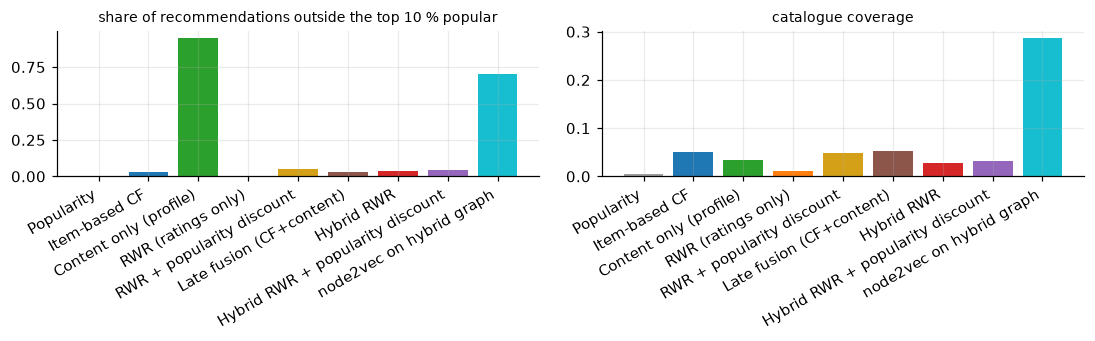

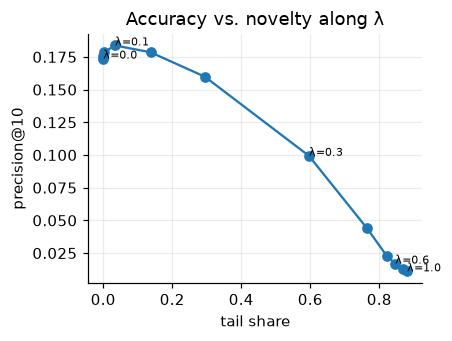

In [13]:
pop = table("main", {"tail": "outside top-10% popular", "coverage": "catalogue coverage", "mean_pop": "mean log(1+#ratings)"}, names)
pop.insert(0, "precision@10", [f"{meanstd('main', n, 'p')[0]:.3f}" for n in names])
display(pop); open("report/tables/popularity.tex", "w").write(pop.to_latex(escape=True, column_format="lcccc"))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for a, m, lab in [(ax[0], "tail", "share of recommendations outside the top 10 % popular"), (ax[1], "coverage", "catalogue coverage")]:
    mu = [meanstd("main", n, m)[0] for n in names]; a.bar(range(len(names)), mu, color=[COL[n] for n in names])
    a.set_xticks(range(len(names))); a.set_xticklabels(names, rotation=30, ha="right"); a.set_title(lab, fontsize=9)
plt.tight_layout(); savefig("fig_popularity"); plt.show()
# accuracy–novelty trade-off: sweep λ and β jointly on one split would be costly; the λ sweep above already shows tail share vs precision
cv_p, cv_t = curve("lam_sweep", "p").mean(0), curve("lam_sweep", "tail").mean(0)
plt.figure(figsize=(4.2, 3.2)); plt.plot(cv_t, cv_p, "o-"); [plt.annotate(f"λ={l}", (t, p), fontsize=7) for l, t, p in zip(lams, cv_t, cv_p) if l in (0, .1, .3, .6, 1)]
plt.xlabel("tail share"); plt.ylabel("precision@10"); plt.title("Accuracy vs. novelty along λ"); plt.tight_layout(); savefig("fig_tradeoff"); plt.show()

## 10. Communities of taste — project onto users

Project the user–film graph onto **users** (cosine of mean-centred rating vectors; each user linked to their 15 most similar users), detect communities with Louvain, and ask whether the communities follow genres. We use the genre profile of each user = share of the films they *liked* in each genre. The communities are built from ratings only, so any genre structure is discovered, not imposed. Test: between-community spread of genre profiles against 2000 random relabelings of users that keep the community sizes (permutation test).

communities: 6 sizes: [158, 123, 101, 95, 85, 48] | modularity Q = 0.406


between-community genre spread: observed 1.031, permutation mean 0.153 (sd 0.042), p = 0.0005, z = 20.7


NMI(community, user's dominant genre) = 0.066 (permutation mean 0.029)


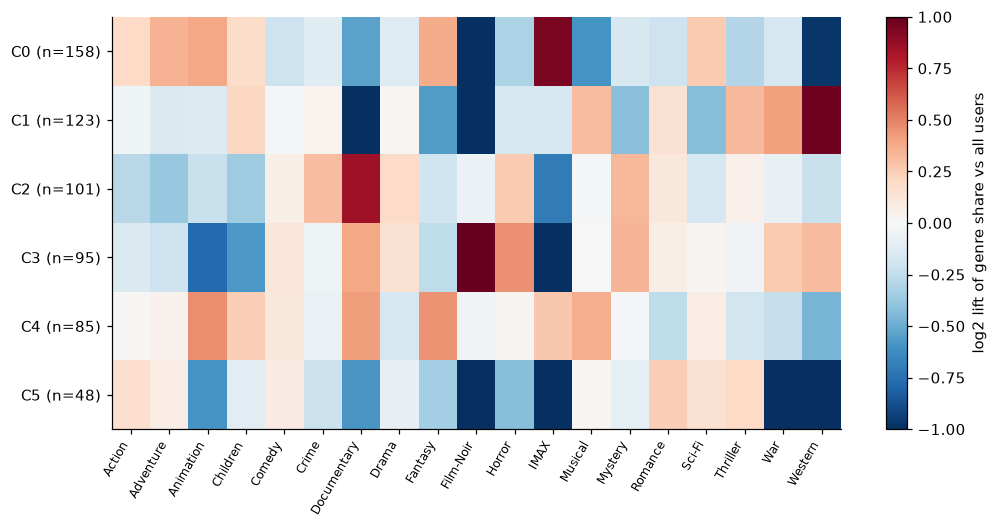

,community,users,over-represented genres,under-represented
0,C0,158,"IMAX (1.92×), Animation (1.31×), Fantasy (1.30×)","Western (0.51×), Film-Noir (0.41×)"
1,C1,123,"Western (1.96×), War (1.33×), Thriller (1.25×)","Documentary (0.40×), Film-Noir (0.24×)"
2,C2,101,"Documentary (1.80×), Mystery (1.26×), Crime (1...","Adventure (0.77×), IMAX (0.62×)"
3,C3,95,"Film-Noir (3.35×), Horror (1.37×), Documentary...","Animation (0.58×), IMAX (0.21×)"
4,C4,85,"Animation (1.38×), Fantasy (1.36×), Documentar...","Romance (0.84×), Western (0.73×)"
5,C5,48,"Romance (1.19×), Thriller (1.15×), Action (1.12×)","Film-Noir (0.36×), IMAX (0.24×)"


748

In [14]:
Wuu = H.user_projection(R, nU, nI, k=15)
lab, Q = H.louvain(Wuu, seed=0)
sizes = np.bincount(lab); print("communities:", len(sizes), "sizes:", sizes.tolist(), "| modularity Q = %.3f" % Q)
genres = sorted({g for gs in M.genres for g in gs.split("|") if g != "(no genres listed)"})
GP = H.genre_profiles(R, M, nU, genres)
glob = GP.mean(0)
def spread(labels):
    return sum((labels == c).sum() * ((GP[labels == c].mean(0) - glob) ** 2).sum() for c in np.unique(labels))
obs = spread(lab); rng = np.random.default_rng(0)
null = np.array([spread(rng.permutation(lab)) for _ in range(2000)])
print("between-community genre spread: observed %.3f, permutation mean %.3f (sd %.3f), p = %.4f, z = %.1f" % (obs, null.mean(), null.std(), (1 + (null >= obs).sum()) / 2001, (obs-null.mean())/null.std()))
from sklearn.metrics import normalized_mutual_info_score as nmi
dom = GP.argmax(1); print("NMI(community, user's dominant genre) = %.3f (permutation mean %.3f)" % (nmi(lab, dom), np.mean([nmi(rng.permutation(lab), dom) for _ in range(200)])))
big = [c for c in range(len(sizes)) if sizes[c] >= 20]
lift = np.array([GP[lab == c].mean(0) / np.maximum(glob, 1e-9) for c in big])
fig, ax = plt.subplots(figsize=(9.5, 0.55*len(big)+1.6))
im = ax.imshow(np.log2(lift), cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(genres))); ax.set_xticklabels(genres, rotation=60, ha="right", fontsize=8); ax.set_yticks(range(len(big))); ax.set_yticklabels([f"C{c} (n={sizes[c]})" for c in big])
plt.colorbar(im, label="log2 lift of genre share vs all users"); ax.grid(False); plt.tight_layout(); savefig("fig_communities"); plt.show()
rows = []
for c in big:
    l = pd.Series(lift[big.index(c)], index=genres).sort_values(ascending=False)
    rows.append({"community": f"C{c}", "users": sizes[c], "over-represented genres": ", ".join(f"{g} ({v:.2f}×)" for g, v in l.head(3).items()),
                 "under-represented": ", ".join(f"{g} ({v:.2f}×)" for g, v in l.tail(2).items())})
com = pd.DataFrame(rows); display(com); open("report/tables/communities.tex", "w").write(com.to_latex(index=False, escape=True, column_format="llp{5cm}p{4cm}"))

In [15]:
# Are the communities also *structurally* separated? share of user-user edge weight kept inside communities
Wc = Wuu.tocoo(); inside = Wc.data[lab[Wc.row] == lab[Wc.col]].sum() / Wc.data.sum()
print(f"share of user–user similarity inside communities: {inside:.2f}")

share of user–user similarity inside communities: 0.61


## 11. Demo

We now use **all** ratings (no hidden test set), the validated hyper-parameters from split 0, and show what each method recommends for a real user — and then add films that nobody has rated.

### 11a. One user, every method side by side

User 105 rated *3 Idiots* and *Taare Zameen Par* (the example in the brief) highly. What should come next?

In [16]:
p0 = res[0]["params"]; print("hyper-parameters:", p0)
Cm = Cs[p0["k"]]
S_icf = H.item_cf_scores(ctx_full); S_ct = H.content_profile_scores(ctx_full, E)
S_cf = H.rwr_scores(ctx_full, Cm, 0.0, p0["c"]); S_h = H.rwr_scores(ctx_full, Cm, p0["lam"], p0["c"])
S_hd = H.debias(H.rwr_scores(ctx_full, Cm, p0["lam_debias"], p0["c"]), ctx_full.pop, p0["beta_hyb"])
S_n2v = H.node2vec_scores(H.build_P(ctx_full.A, Cm, p0["lam"]), nU)
demo_methods = {"Item-based CF": S_icf, "RWR (ratings)": S_cf, "Content only": S_ct, "Hybrid RWR": S_h, "Hybrid + pop. discount": S_hd, "node2vec": S_n2v}
def show_user(u, k=10):
    liked = ctx_full.Liked[u]; fav = liked.indices[np.argsort(-liked.data)][:10]
    print(f"userId {u+1} — liked {liked.nnz} films; favourites:", "; ".join(title[fav]))
    tops = {n: H.top_k(S, ctx_full, k)[u] for n, S in demo_methods.items()}
    return pd.DataFrame({n: [f"{title[i]}  [{ctx_full.pop[i]}]" for i in t] for n, t in tops.items()}, index=range(1, k+1))
demo = show_user(104)
pd.set_option("display.max_colwidth", 60); display(demo)
demo.to_latex("report/tables/demo_user.tex", escape=True, column_format="l" + "p{2.6cm}"*6)

hyper-parameters: {'c': 0.7, 'lam': 0.1, 'lam_debias': 0.05, 'beta_cf': 0.5, 'beta_hyb': 0.2, 'alpha': 0.05, 'k': 20}


userId 105 — liked 554 films; favourites: Loving Vincent (2017); Bobik Visiting Barbos (1977); Seven (a.k.a. Se7en) (1995); Usual Suspects, The (1995); In the blue sea, in the white foam. (1984); On the Trail of the Bremen Town Musicians (1973); Gena the Crocodile (1969); The Bremen Town Musicians (1969); Planet Earth (2006); Winnie Pooh (1969)


,Item-based CF,RWR (ratings),Content only,Hybrid RWR,Hybrid + pop. discount,node2vec
1,"Truman Show, The (1998) [125]",Star Wars: Episode V - The Empire Strikes Back (1980) [...,The Way (2010) [2],Star Wars: Episode V - The Empire Strikes Back (1980) [...,Star Wars: Episode V - The Empire Strikes Back (1980) [...,My Bloody Valentine (1981) [1]
2,"Big Lebowski, The (1998) [106]",Star Wars: Episode VI - Return of the Jedi (1983) [196],In This World (2002) [2],Star Wars: Episode VI - Return of the Jedi (1983) [196],Star Wars: Episode VI - Return of the Jedi (1983) [196],Rivers and Tides (2001) [1]
3,Star Wars: Episode V - The Empire Strikes Back (1980) [...,Toy Story (1995) [215],"Way, Way Back, The (2013) [4]",Toy Story (1995) [215],Toy Story (1995) [215],Bakuman (2015) [1]
4,Monty Python and the Holy Grail (1975) [136],Back to the Future (1985) [171],Fun (1994) [1],Back to the Future (1985) [171],Back to the Future (1985) [171],Night Guards (2016) [1]
5,Signs (2002) [63],Monty Python and the Holy Grail (1975) [136],Jump In! (2007) [1],Jurassic Park (1993) [238],Monty Python and the Holy Grail (1975) [136],Asterix and the Vikings (Astérix et les Vikings) (2006) ...
6,Star Wars: Episode VI - Return of the Jedi (1983) [196],Jurassic Park (1993) [238],"Ex, The (2007) [1]","Lion King, The (1994) [172]","Truman Show, The (1998) [125]",War Dance (2007) [1]
7,Back to the Future (1985) [171],"Truman Show, The (1998) [125]",Beautiful (2000) [2],Monty Python and the Holy Grail (1975) [136],"Lion King, The (1994) [172]",Hot Girls Wanted (2015) [1]
8,King Kong (2005) [40],"Lion King, The (1994) [172]",Enough Said (2013) [2],"Truman Show, The (1998) [125]","Big Lebowski, The (1998) [106]",Sherlock Holmes: Terror by Night (1946) [1]
9,Ferris Bueller's Day Off (1986) [109],"Princess Bride, The (1987) [142]",Without a Clue (1988) [1],Die Hard (1988) [145],Jurassic Park (1993) [238],Kizumonogatari Part 1: Tekketsu (2016) [1]
10,Hellboy (2004) [41],Die Hard (1988) [145],[REC] (2007) [8],Indiana Jones and the Last Crusade (1989) [140],"Princess Bride, The (1987) [142]",The Blue Planet (2001) [2]


The number in brackets is the film's number of ratings. Item-based CF and the plain walk return blockbusters; content-only returns films on the same subject but often unknown ones; the hybrid mixes both.

### 11b. A new film with no ratings --- which users should get it?

A new film has no rating edge, so collaborative methods cannot reach it at all. We add films that are **not in the data set**, described the way a catalogue would (title, genres, a few tags), embed their text, link each to its 20 nearest films, and run the hybrid walk from every user. Scores of a film are not comparable between users (a user with few ratings concentrates the walk), so, exactly as in the cold-start evaluation, we compare the new film with the other **new releases** (all films from 2015 on that the user has not seen): the user's *percentile* is the film's rank among them (1\,\% = first on that user's new-release shelf). We list the users it ranks highest for, and check the choice against **anchor films** that a sensible match should have liked (e.g.\ *Toy Story 4* should go to users who liked the earlier *Toy Story* films).

In [17]:
from sentence_transformers import SentenceTransformer
st = SentenceTransformer("all-MiniLM-L6-v2")
yr = M.title.str.extract(r"\((\d{4})\)\s*$")[0].astype(float).values
recent = np.where(yr >= 2015)[0]; print(len(recent), "films from 2015 on form the 'new releases' shelf")
def idx_of(sub): return M.index[M.title.str.contains(sub, regex=False)].values
new_films = {
 "Toy Story 4 (2019)": ("Toy Story 4. Genres: Adventure, Animation, Children, Comedy, Fantasy. Tags: pixar, toys, fun", idx_of("Toy Story")),
 "John Wick: Chapter 3 (2019)": ("John Wick Chapter 3 Parabellum. Genres: Action, Crime, Thriller. Tags: assassin, hitman, gun fu, keanu reeves", idx_of("John Wick")),
 "Dangal (2016)": ("Dangal. Genres: Action, Drama. Tags: wrestling, sports, father daughter, india, inspirational, bollywood", np.concatenate([idx_of("Lagaan"), idx_of("3 Idiots"), idx_of("Taare Zameen Par"), idx_of("Slumdog")])),
}
def recommend_new_film(text, lam, c, k=20):
    e = st.encode([text], normalize_embeddings=True).astype(np.float32)
    E2 = np.vstack([E, e]); C2 = H.knn_graph(E2, k)
    A2 = sp.hstack([ctx_full.A, sp.csr_matrix((nU, 1), dtype=np.float32)], format="csr")
    S = H.rwr_all(H.build_P(A2, C2, lam), nU, c)                      # users x (films + 1)
    S[ctx_full.seen_r, ctx_full.seen_c] = -np.inf                     # drop films the user rated
    pool = np.append(recent, nI)                                       # new releases + the new film
    Sp = S[:, pool]
    s_new = Sp[:, -1]
    n_unseen = np.isfinite(Sp).sum(1)
    pct = ((Sp > s_new[:, None]).sum(1) + 1) / n_unseen * 100
    nb = np.argsort(-C2[nI].toarray().ravel())[:5]
    return s_new, pct, nb
rows, summ = [], []
for name, (text, anchors) in new_films.items():
    s_new, pct, nb = recommend_new_film(text, p0["lam"], p0["c"])
    print(f"=== {name} — content neighbours it was linked to: " + "; ".join(title[nb]))
    print(f"    pure CF: score is exactly 0 for all users; hybrid gives it a non-zero score for {(s_new>0).sum()} of {nU} users")
    order = np.argsort(pct)[:20]
    liked_anchor = np.asarray(ctx_full.Liked[:, anchors].sum(1)).ravel() > 0
    summ.append({"new film": name, "top-20 users who liked an anchor film": f"{liked_anchor[order].mean():.0%}",
                 "all users": f"{liked_anchor.mean():.0%}", "lift": f"{liked_anchor[order].mean()/liked_anchor.mean():.1f}x",
                 "median percentile of top-20": f"{np.median(pct[order]):.1f}%"})
    for u in order[:5]:
        fav = ctx_full.Liked[u].indices[np.argsort(-ctx_full.Liked[u].data)][:3]
        rows.append({"new film": name, "user": u+1, "percentile": f"{pct[u]:.1f}%", "user's top films": "; ".join(title[fav])})
summ = pd.DataFrame(summ); rows = pd.DataFrame(rows)
display(summ); display(rows)
summ.to_latex("report/tables/newfilm_summary.tex", index=False, escape=True, column_format="lcccc")
rows.to_latex("report/tables/newfilm_users.tex", index=False, escape=True, column_format="llcp{6cm}")

Loading weights:   0%|                                                                                                      | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|█████████████████████████████████████████████████████████████████████████████████████████| 103/103 [00:00<00:00, 10880.85it/s]

680 films from 2015 on form the 'new releases' shelf


=== Toy Story 4 (2019) — content neighbours it was linked to: Toy Story (1995); Toy Story 3 (2010); Toy Story 2 (1999); Toys (1992); Bug's Life, A (1998)
    pure CF: score is exactly 0 for all users; hybrid gives it a non-zero score for 610 of 610 users


=== John Wick: Chapter 3 (2019) — content neighbours it was linked to: John Wick: Chapter Two (2017); John Wick (2014); Lethal Weapon 3 (1992); Lethal Weapon 4 (1998); Gunman, The (2015)
    pure CF: score is exactly 0 for all users; hybrid gives it a non-zero score for 610 of 610 users


=== Dangal (2016) — content neighbours it was linked to: Bollywood/Hollywood (2002); Krabat (2008); Wrestler, The (2008); Special (2006); Dance of Reality, The (Danza de la realidad, La) (2013)
    pure CF: score is exactly 0 for all users; hybrid gives it a non-zero score for 610 of 610 users


,new film,top-20 users who liked an anchor film,all users,lift,median percentile of top-20
0,Toy Story 4 (2019),75%,28%,2.7x,1.2%
1,John Wick: Chapter 3 (2019),10%,3%,3.0x,6.5%
2,Dangal (2016),20%,8%,2.4x,24.3%


,new film,user,percentile,user's top films
0,Toy Story 4 (2019),259,0.1%,Twelve Monkeys (a.k.a. 12 Monkeys) (1995); Contact (1997...
1,Toy Story 4 (2019),396,0.3%,Toy Story (1995); Léon: The Professional (a.k.a. The Pro...
2,Toy Story 4 (2019),185,0.3%,"Life Less Ordinary, A (1997); Singin' in the Rain (1952)..."
3,Toy Story 4 (2019),500,0.4%,"Living in Oblivion (1995); Wag the Dog (1997); Lock, Sto..."
4,Toy Story 4 (2019),234,0.4%,Toy Story (1995); Powder (1995); Pocahontas (1995)
5,John Wick: Chapter 3 (2019),55,2.1%,"Lock, Stock & Two Smoking Barrels (1998); Layer Cake (20..."
6,John Wick: Chapter 3 (2019),203,4.1%,Braveheart (1995); Pulp Fiction (1994); Contact (1997)
7,John Wick: Chapter 3 (2019),413,4.1%,Casino (1995); Pulp Fiction (1994); Shawshank Redemption...
8,John Wick: Chapter 3 (2019),189,4.6%,"Dark Knight, The (2008); Schindler's List (1993); Bourne..."
9,John Wick: Chapter 3 (2019),231,5.3%,Terminator 2: Judgment Day (1991); Die Hard (1988); Alie...


**Anchor films:** *Toy Story 4*: every film with ``Toy Story'' in its title; *John Wick: Chapter 3*: the earlier *John Wick* films; *Dangal*: the four Indian films in the data (*Lagaan*, *3 Idiots*, *Taare Zameen Par*, *Slumdog Millionaire*).

### 11c. Hide a real film and recover its audience

A check against ground truth: we hide **all** ratings of five well-known films (plus a random 10 % of films, to form a pool), build the hybrid without them, and for each hidden film ask which users it would be sent to. Hits = users among the top 10 who really liked it; the expectation for random users is $10\times$ the share of users who liked the film.

In [18]:
named = {n: int(idx_of(n)[0]) for n in ["Shrek (2001)", "Toy Story 2 (1999)", "Matrix, The (1999)", "Lion King, The (1994)", "Gladiator (2000)"]}
rng = np.random.default_rng(7)
cold = np.union1d(H.cold_films(R, rng), list(named.values()))
mk = R.i.isin(cold).values
ctx_c = H.Ctx(R[~mk], R[mk], nU, nI)
cand = np.zeros(nI, bool); cand[cold] = True
S_c = H.rwr_scores(ctx_c, Cm, p0["lam"], p0["c"])
S_icf_c = H.item_cf_scores(ctx_c)
cols = np.where(cand)[0]; pos = {j: k for k, j in enumerate(cols)}
def user_rank(S):
    Sc = S[:, cols].copy(); Sc[Sc == 0] = np.random.default_rng(0).random(int((Sc == 0).sum())) * 1e-30
    return np.argsort(np.argsort(-Sc, axis=1), axis=1)
rk_h, rk_c = user_rank(S_c), user_rank(S_icf_c)
rows = []
for n, j in named.items():
    likers = ctx_c.rel[:, j]; k = pos[j]
    th = np.argsort(rk_h[:, k] + np.random.default_rng(1).random(nU)*1e-3)[:10]
    tc = np.argsort(rk_c[:, k] + np.random.default_rng(1).random(nU)*1e-3)[:10]
    rows.append({"hidden film": n, "users who liked it": int(likers.sum()), "expected by chance (of 10)": f"{10*likers.mean():.1f}",
                 "hybrid hits (of 10)": int(likers[th].sum()), "item-CF hits (of 10)": int(likers[tc].sum())})
hid = pd.DataFrame(rows); display(hid)
print("mean hits: hybrid %.1f, item-CF %.1f, chance %.1f" % (hid["hybrid hits (of 10)"].mean(), hid["item-CF hits (of 10)"].mean(), hid["expected by chance (of 10)"].astype(float).mean()))
hid.to_latex("report/tables/hidden_films.tex", index=False, escape=True, column_format="lcccc")

,hidden film,users who liked it,expected by chance (of 10),hybrid hits (of 10),item-CF hits (of 10)
0,Shrek (2001),114,1.9,2,2
1,Toy Story 2 (1999),56,0.9,2,1
2,"Matrix, The (1999)",222,3.6,4,4
3,"Lion King, The (1994)",115,1.9,4,0
4,Gladiator (2000),117,1.9,3,1


mean hits: hybrid 3.0, item-CF 1.6, chance 2.0


## 12. Summary of findings

The numbers are in the tables above and in the report (`report/report.pdf`); the discussion there answers each of the brief's investigation questions. Reproduce everything with: `python3 build/make_full_nb.py` then execute this notebook (cached seed results are in `results/`).

**Citations.** Linden, Smith & York (2003); Fouss, Pirotte, Renders & Saerens (2007); Harper & Konstan (2015); Page, Brin, Motwani & Winograd (1999); Grover & Leskovec (2016); Perozzi, Al-Rfou & Skiena (2014); Reimers & Gurevych (2019); Blondel et al. (2008) for Louvain; Hagberg et al. (2008) for NetworkX; Paszke et al. (2019) for PyTorch.